# Bagging and Restart-Ensemble Experiment

## Why add ensembles?

The six-supergroup retrieval experiment compared one selected PLSA fit with full-data TF-IDF and LSI. In that run, PLSA's single best-restart model performed poorly. We then tested aggregation because PLSA uses stochastic EM and different fits can produce different document rankings. The preliminary PLSA-only ensemble looked promising, but it was not a fair ensemble comparison while TF-IDF and LSI were represented by only one model each.

This experiment applies five-member bootstrap ensembles to PLSA, TF-IDF, and LSI. Each member is trained from a same-size sample drawn with replacement from the entire training partition, and all three methods use the same five saved resamples. We combine rankings by mean rank because raw scores from the three model families are on different scales. Alongside the full-data references, PLSA also has a five-restart ensemble trained on the complete training data; that control helps show what aggregation across random initializations can achieve without bootstrap resampling.

The retrieval task remains the same six human-defined supergroups, one fixed query per group, and the same held-out candidates. This isolates the ensemble question within the task already established in `Six_Category_Experiment.ipynb`.


## Environment

The next cell contains the optional dependency-install command for notebook environments where these packages are not already available.


In [1]:
# %pip -q install numpy scipy scikit-learn pandas matplotlib


## 1. Libraries and shared settings

The imports cover sparse count matrices and PLSA, TF-IDF and LSI, the shared split and supergroup mapping, retrieval scoring, and result tables and plots.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42



## 2. Reuse the six-supergroup evaluation design

The same mapping of all 20 categories into six topical groups is declared here so this notebook can run independently. It defines stratification and relevance; the labels are not inputs to PLSA training. Keeping the mapping, split, text processing, queries, and held-out candidates aligned with the preceding experiment makes the ensemble comparison address model aggregation rather than a different retrieval task.


In [3]:
SUPERGROUPS = {
    "Computing": [
        "comp.graphics",
        "comp.os.ms-windows.misc",
        "comp.sys.ibm.pc.hardware",
        "comp.sys.mac.hardware",
        "comp.windows.x",
    ],
    "Digital technology and engineering": ["sci.crypt", "sci.electronics"],
    "Health and space science": ["sci.med", "sci.space"],
    "Recreation and consumer exchange": [
        "misc.forsale", "rec.autos", "rec.motorcycles",
        "rec.sport.baseball", "rec.sport.hockey"
    ],
    "Religion and worldview": [
        "alt.atheism", "soc.religion.christian", "talk.religion.misc"
    ],
    "Politics and international affairs": [
        "talk.politics.guns", "talk.politics.mideast", "talk.politics.misc"
    ],
}

dataset = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=SEED
)
documents = np.array(dataset.data, dtype=object)
original_labels = np.asarray(dataset.target)
source_category_names = list(dataset.target_names)

all_mapped_categories = [name for members in SUPERGROUPS.values() for name in members]
missing_categories = sorted(set(source_category_names) - set(all_mapped_categories))
unknown_categories = sorted(set(all_mapped_categories) - set(source_category_names))
duplicate_categories = sorted({name for name in all_mapped_categories if all_mapped_categories.count(name) > 1})
if missing_categories or unknown_categories or duplicate_categories:
    raise ValueError(
        f"Supergroup mapping must cover each source category once. Missing={missing_categories}; "
        f"unknown={unknown_categories}; duplicates={duplicate_categories}"
    )

source_to_supergroup = {
    category: group
    for group, members in SUPERGROUPS.items()
    for category in members
}
target_names = list(SUPERGROUPS)
supergroup_to_id = {name: i for i, name in enumerate(target_names)}
labels = np.asarray([
    supergroup_to_id[source_to_supergroup[source_category_names[label]]]
    for label in original_labels
], dtype=int)

print("Source categories:", len(source_category_names))
print("Evaluation supergroups:", len(target_names))
print("Total documents:", len(documents))
for group_id, group_name in enumerate(target_names):
    member_categories = SUPERGROUPS[group_name]
    count = int((labels == group_id).sum())
    print(f"\n{group_name}: {count} documents")
    for category in member_categories:
        source_id = source_category_names.index(category)
        print(f"  - {category}: {int((original_labels == source_id).sum())} documents")

print("\nAll 20 original categories are assigned exactly once.")
print("Supergroup labels are used for stratification and retrieval evaluation; PLSA fitting remains unsupervised.")


Source categories: 20
Evaluation supergroups: 6
Total documents: 18846

Computing: 4891 documents
  - comp.graphics: 973 documents
  - comp.os.ms-windows.misc: 985 documents
  - comp.sys.ibm.pc.hardware: 982 documents
  - comp.sys.mac.hardware: 963 documents
  - comp.windows.x: 988 documents

Digital technology and engineering: 1975 documents
  - sci.crypt: 991 documents
  - sci.electronics: 984 documents

Health and space science: 1977 documents
  - sci.med: 990 documents
  - sci.space: 987 documents

Recreation and consumer exchange: 4954 documents
  - misc.forsale: 975 documents
  - rec.autos: 990 documents
  - rec.motorcycles: 996 documents
  - rec.sport.baseball: 994 documents
  - rec.sport.hockey: 999 documents

Religion and worldview: 2424 documents
  - alt.atheism: 799 documents
  - soc.religion.christian: 997 documents
  - talk.religion.misc: 628 documents

Politics and international affairs: 2625 documents
  - talk.politics.guns: 910 documents
  - talk.politics.mideast: 940 d

### Corpus and group counts

The output confirms that all 20 categories are assigned once and that the full 18,846-document corpus is used. Group sizes remain naturally different; no training examples are discarded to equalize them. This is the same relevance taxonomy used in the six-supergroup retrieval experiment.


## 3. Shared split and preprocessing

Use a stratified 80/20 split and fit the 3,000-term vocabulary on training text only. The bootstrap samples will be drawn from the complete training partition. Every method will rank the same non-empty test documents.


In [4]:
import spacy
docs_train, docs_test, y_train, y_test, original_y_train, _ = train_test_split(
    documents,
    labels,
    original_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

print("Training documents per supergroup:", dict(zip(target_names, np.bincount(y_train, minlength=len(target_names)))))
print("Training documents retained:", len(docs_train), "of", len(documents))
print("Held-out test documents retained:", len(docs_test), "of", len(documents))

nlp = spacy.load(
    "en_core_web_sm",
    disable=["ner", "parser"]
)

def preprocess_texts(texts):
    """
    Lowercase, tokenize, remove stop words and punctuation,
    and lemmatize the remaining tokens.

    Returns a list of preprocessed document strings.
    """
    processed_docs = []

    for doc in nlp.pipe(texts, batch_size=256):
        tokens = []

        for token in doc:

            if (
                token.is_space
                or token.is_punct
                or token.like_num
                or not token.is_alpha
            ):
                continue

            if token.is_stop:
                continue

            lemma = token.lemma_.lower().strip()

            if len(lemma) < 2:
                continue

            tokens.append(lemma)

        processed_docs.append(" ".join(tokens))

    return processed_docs

docs_train_processed = preprocess_texts(docs_train)
docs_test_processed = preprocess_texts(docs_test)
nonempty_test_mask = np.asarray([bool(doc.strip()) for doc in docs_test_processed])

count_vectorizer = CountVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    max_features=3000,
    min_df=3,
    max_df=0.90,
    dtype=np.float64
)

X_train = count_vectorizer.fit_transform(
    docs_train_processed
)

X_test = count_vectorizer.transform(
    docs_test_processed
)

vocabulary = count_vectorizer.get_feature_names_out()

print("X_train:", X_train.shape, "(documents, vocabulary)")
print("X_test: ", X_test.shape)
print("Example vocabulary:", vocabulary[:20])

print(
    "Empty training documents after preprocessing:",
    sum(not doc.strip() for doc in docs_train_processed)
)

print(
    "Empty test documents after preprocessing:",
    sum(not doc.strip() for doc in docs_test_processed)
)


Training documents per supergroup: {'Computing': 3913, 'Digital technology and engineering': 1580, 'Health and space science': 1581, 'Recreation and consumer exchange': 3963, 'Religion and worldview': 1939, 'Politics and international affairs': 2100}
Training documents retained: 15076 of 18846
Held-out test documents retained: 3770 of 18846
X_train: (15076, 3000) (documents, vocabulary)
X_test:  (3770, 3000)
Example vocabulary: ['aaron' 'abandon' 'abc' 'abide' 'ability' 'able' 'abortion' 'absolute'
 'absolutely' 'abstract' 'abuse' 'ac' 'academic' 'accelerator' 'accept'
 'acceptable' 'access' 'accident' 'accomplish' 'accord']
Empty training documents after preprocessing: 446
Empty test documents after preprocessing: 121


### Split and text representation

The split retains 15,076 training and 3,770 held-out documents. The shared count vocabulary has 3,000 terms; documents emptied by preprocessing have no usable vector and are excluded from retrieval rankings. The labels affect stratification and later scoring only.

## 4. PLSA representation

PLSA represents each document as a mixture over latent topics and each topic as a distribution over words. EM estimates these distributions from word counts. The class below uses sparse input matrices; it does not use Newsgroups labels in its updates.


In [5]:
class PLSA:
    """PLSA trained directly with NumPy EM and sparse input counts."""

    def __init__(self, n_topics=5, max_iter=100, tol=1e-4,
                 random_state=42, beta=1.0):
        if n_topics < 1:
            raise ValueError("n_topics must be positive")
        if not (0 < beta):
            raise ValueError("beta must be positive")
        self.n_topics = n_topics
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.beta = beta
        self.log_likelihoods = []

    @staticmethod
    def _normalize(a, axis):
        denom = np.maximum(a.sum(axis=axis, keepdims=True), 1e-15)
        return a / denom

    @staticmethod
    def _observations(X):
        X = csr_matrix(X, dtype=np.float64)
        X.eliminate_zeros()
        X.sum_duplicates()
        docs, words, counts = [], [], []
        for d in range(X.shape[0]):
            start, end = X.indptr[d], X.indptr[d + 1]
            if end > start:
                docs.append(np.full(end-start, d, dtype=np.int64))
                words.append(X.indices[start:end].astype(np.int64))
                counts.append(X.data[start:end].astype(np.float64))
        if not docs:
            raise ValueError("Input has no observed word counts.")
        return X, np.concatenate(docs), np.concatenate(words), np.concatenate(counts)

    def fit(self, X):
        X, doc_ids, word_ids, counts = self._observations(X)
        D, V = X.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state)

        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)
        phi = self._normalize(rng.random((K, V)) + 1e-3, axis=1)
        self.log_likelihoods = []

        for iteration in range(self.max_iter):

            unnorm = theta[doc_ids].T * phi[:, word_ids]
            if self.beta != 1.0:
                unnorm = np.maximum(unnorm, 1e-15) ** self.beta
            posterior = unnorm / np.maximum(
                unnorm.sum(axis=0, keepdims=True), 1e-15
            )

            weighted = posterior * counts[None, :]
            topic_word = np.zeros((K, V), dtype=np.float64)
            doc_topic = np.zeros((D, K), dtype=np.float64)

            for k in range(K):
                np.add.at(topic_word[k], word_ids, weighted[k])
                np.add.at(doc_topic[:, k], doc_ids, weighted[k])

            phi = self._normalize(topic_word + 1e-12, axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)

            p_observed = np.sum(theta[doc_ids] * phi[:, word_ids].T, axis=1)
            ll = float(np.sum(counts * np.log(np.maximum(p_observed, 1e-15))))
            self.log_likelihoods.append(ll)

            if iteration > 0:
                improvement = ll - previous_ll
                if self.beta == 1.0 and improvement < -1e-7:
                    print("Warning: likelihood decreased slightly; check numerical behavior.")
                if abs(improvement) <= self.tol * (1 + abs(previous_ll)):
                    break
            previous_ll = ll

        self.theta_ = theta
        self.phi_ = phi
        self.n_features_in_ = V
        self.n_iter_ = len(self.log_likelihoods)
        return self

    def transform(self):
        """Document-topic probabilities for the documents used in fit()."""
        return self.theta_

    def fold_in(self, X_new, max_iter=100):
        """Infer P(z|d_new) with learned P(w|z) fixed."""
        X_new = csr_matrix(X_new, dtype=np.float64)
        if X_new.shape[1] != self.n_features_in_:
            raise ValueError("New data must use the same fitted vocabulary.")
        D, V = X_new.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state + 1000)
        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)

        for _ in range(max_iter):
            doc_topic = np.zeros((D, K), dtype=np.float64)
            for d in range(D):
                start, end = X_new.indptr[d], X_new.indptr[d + 1]
                words = X_new.indices[start:end]
                counts = X_new.data[start:end]
                if len(words) == 0:
                    continue
                unnorm = theta[d, :, None] * self.phi_[:, words]
                if self.beta != 1.0:
                    unnorm = np.maximum(unnorm, 1e-15) ** self.beta
                posterior = unnorm / np.maximum(
                    unnorm.sum(axis=0, keepdims=True), 1e-15
                )
                doc_topic[d] = (posterior * counts[None, :]).sum(axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)
        return theta

    def top_words(self, vocabulary, n=10):
        result = {}
        for k, dist in enumerate(self.phi_):
            ids = np.argsort(dist)[::-1][:n]
            result[k] = [(vocabulary[i], float(dist[i])) for i in ids]
        return result


## 5. Full-data PLSA reference and restart control

First fit five PLSA initializations to the complete training matrix using K=6 and the same settings as the preceding experiment. The highest-training-likelihood run is the single-model reference. The five full-data runs are also folded into the held-out documents and retained for a mean-rank ensemble. This restart control combines different initializations without resampling documents.


In [6]:
def train_plsa_restarts(X, n_topics=6, n_restarts=5,
                        max_iter=100, tol=1e-4, base_seed=42):
    runs = []
    for r in range(n_restarts):
        model = PLSA(
            n_topics=n_topics, max_iter=max_iter, tol=tol,
            random_state=base_seed + r, beta=1.0
        ).fit(X)
        final_ll = model.log_likelihoods[-1]
        runs.append((model, final_ll))
        print(f"Restart {r+1}: final training log-likelihood={final_ll:.3f}, "
              f"iterations={model.n_iter_}")
    best_model, best_ll = max(runs, key=lambda item: item[1])
    print("Selected best training likelihood:", round(best_ll, 3))
    return best_model, runs

K = 6
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=5, max_iter=100
)
theta_train = best_plsa.transform()
theta_test = best_plsa.fold_in(X_test, max_iter=100)
print("theta_train:", theta_train.shape)
print("theta_test:", theta_test.shape)


Restart 1: final training log-likelihood=-6273009.364, iterations=44
Restart 2: final training log-likelihood=-6277750.970, iterations=40
Restart 3: final training log-likelihood=-6275103.752, iterations=46
Restart 4: final training log-likelihood=-6277416.226, iterations=51
Restart 5: final training log-likelihood=-6275063.638, iterations=42
Selected best training likelihood: -6273009.364
theta_train: (15076, 6)
theta_test: (3770, 6)


### Full-data PLSA output

The five full-data restarts provide both the single-model reference (the run with the highest training likelihood) and the models for a restart ensemble. The restart ensemble changes the number of rankings combined while keeping the training corpus unchanged.

## 6. Train the PLSA bootstrap members

Each of five members draws 15,076 row indices with replacement from the complete training matrix and fits a fresh K=6 PLSA model. A member therefore repeats some documents and omits others, while every training document remains eligible for selection. The index arrays are saved for reuse by TF-IDF and LSI.

In [7]:
BAGGING_ESTIMATORS = 5
bootstrap_indices_list = []
bagged_plsa_models = []
bootstrap_rng = np.random.default_rng(SEED + 500)
for estimator_id in range(BAGGING_ESTIMATORS):
    bootstrap_indices = bootstrap_rng.integers(0, X_train.shape[0], size=X_train.shape[0])
    bootstrap_indices_list.append(bootstrap_indices)
    bootstrap_X = X_train[bootstrap_indices]
    model = PLSA(
        n_topics=K, max_iter=100, tol=1e-4,
        random_state=SEED + 1000 + estimator_id, beta=1.0
    ).fit(bootstrap_X)
    bagged_plsa_models.append(model)
    print(
        f"Bootstrap model {estimator_id + 1}/{BAGGING_ESTIMATORS}: "
        f"{len(np.unique(bootstrap_indices))} unique training documents, "
        f"final bootstrap log-likelihood={model.log_likelihoods[-1]:.3f}"
    )

bagged_theta_test = [model.fold_in(X_test, max_iter=100) for model in bagged_plsa_models]
restart_theta_test = [model.fold_in(X_test, max_iter=100) for model, _ in restart_runs]
print("Bagged PLSA models:", len(bagged_plsa_models))
print("The saved bootstrap indices will be reused for TF-IDF and LSI.")


Bootstrap model 1/5: 9477 unique training documents, final bootstrap log-likelihood=-6278146.061
Bootstrap model 2/5: 9516 unique training documents, final bootstrap log-likelihood=-6216022.269
Bootstrap model 3/5: 9493 unique training documents, final bootstrap log-likelihood=-5967843.122
Bootstrap model 4/5: 9505 unique training documents, final bootstrap log-likelihood=-6099398.239
Bootstrap model 5/5: 9605 unique training documents, final bootstrap log-likelihood=-6069677.583
Bagged PLSA models: 5
The saved bootstrap indices will be reused for TF-IDF and LSI.


### Bootstrap PLSA output

Each 15,076-row bootstrap sample contains about 9,477–9,605 unique training documents; remaining rows are repeats. The five members therefore see different empirical samples. Their rankings will be combined with mean rank, and their exact indices are shared with the TF-IDF and LSI bootstrap members.

## 7. Full-training TF-IDF and LSI references

Fit each baseline once on the complete 80% training partition. These reference models are compared with five-member bootstrap ensembles fitted using the shared resample indices. The vocabulary and all baseline models are learned from training text only.


In [8]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    max_features=3000,
    min_df=3,
    max_df=0.90
)

X_train_tfidf = tfidf_vectorizer.fit_transform(docs_train_processed)
X_test_tfidf = tfidf_vectorizer.transform(docs_test_processed)

n_components = min(50, X_train_tfidf.shape[0]-1, X_train_tfidf.shape[1]-1)
lsi_model = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    Normalizer(copy=False)
)
lsi_train = lsi_model.fit_transform(X_train_tfidf)
lsi_test = lsi_model.transform(X_test_tfidf)

print("TF-IDF train/test:", X_train_tfidf.shape, X_test_tfidf.shape)
print("LSI train/test:", lsi_train.shape, lsi_test.shape)


TF-IDF train/test: (15076, 3000) (3770, 3000)
LSI train/test: (15076, 50) (3770, 50)


### Full-data baseline output

TF-IDF uses the training-only 3,000-term representation, and LSI projects it into 50 dimensions. These full-training models are the non-ensemble references for their method families.

## 8. Fit bootstrap TF-IDF and LSI members

For each saved resample, fit a fresh TF-IDF vocabulary and IDF weights, then fit a fresh 50-dimensional LSI space in that member's vocabulary. Every member transforms the same held-out documents. Re-fitting within each sample is part of the bootstrap procedure; sharing the indices pairs the document draws across model families.

In [9]:
bagged_tfidf_vectorizers = []
bagged_tfidf_test = []
bagged_lsi_models = []
bagged_lsi_test = []

for member_id, bootstrap_indices in enumerate(bootstrap_indices_list):
    bootstrap_docs = [docs_train_processed[i] for i in bootstrap_indices]
    member_vectorizer = TfidfVectorizer(
        lowercase=False,
        tokenizer=str.split,
        token_pattern=None,
        max_features=3000,
        min_df=3,
        max_df=0.90
    )
    member_train_tfidf = member_vectorizer.fit_transform(bootstrap_docs)
    member_test_tfidf = member_vectorizer.transform(docs_test_processed)
    member_components = min(50, member_train_tfidf.shape[0] - 1, member_train_tfidf.shape[1] - 1)
    member_lsi = make_pipeline(
        TruncatedSVD(n_components=member_components, random_state=SEED + 1200 + member_id),
        Normalizer(copy=False)
    )
    member_lsi.fit_transform(member_train_tfidf)
    member_test_lsi = member_lsi.transform(member_test_tfidf)
    bagged_tfidf_vectorizers.append(member_vectorizer)
    bagged_tfidf_test.append(member_test_tfidf)
    bagged_lsi_models.append(member_lsi)
    bagged_lsi_test.append(member_test_lsi)
    print(
        f"Baseline bootstrap {member_id + 1}/{BAGGING_ESTIMATORS}: "
        f"TF-IDF shape={member_train_tfidf.shape}, LSI dimensions={member_components}"
    )


Baseline bootstrap 1/5: TF-IDF shape=(15076, 3000), LSI dimensions=50
Baseline bootstrap 2/5: TF-IDF shape=(15076, 3000), LSI dimensions=50
Baseline bootstrap 3/5: TF-IDF shape=(15076, 3000), LSI dimensions=50
Baseline bootstrap 4/5: TF-IDF shape=(15076, 3000), LSI dimensions=50
Baseline bootstrap 5/5: TF-IDF shape=(15076, 3000), LSI dimensions=50


### Bootstrap baseline output

Five TF-IDF and five LSI members were fitted from the same resampled document indices as the PLSA members. Each model family keeps its own fitted vocabulary and latent space, while all members rank the same held-out documents.


## 9. Retrieval metrics and queries

Each of the six broad supergroups has one fixed query, and relevance means membership in that supergroup. All methods rank the same non-empty held-out candidates. The table reports every query and the macro-average, giving each query equal weight.

Precision@10 and Recall@10 use the top ten. AP@10 averages precision at relevant ranks through rank 10, normalized by the smaller of ten and the number of relevant held-out documents; MAP@10 is the mean over six queries. NDCG@10 uses binary relevance and rank discounts. These category labels are proxy relevance judgments.


In [10]:
supergroup_queries = {
    "Computing": "computer graphics software hardware operating systems windows",
    "Digital technology and engineering": "electronics circuits encryption cryptography hardware",
    "Health and space science": "medicine health disease doctor space NASA planet",
    "Recreation and consumer exchange": "cars motorcycles baseball hockey sports sale price",
    "Religion and worldview": "religion atheist christian belief faith god",
    "Politics and international affairs": "politics government guns international middle east policy",
}

missing = sorted(set(target_names) - set(supergroup_queries))
extra = sorted(set(supergroup_queries) - set(target_names))
print("Supergroups without a query:", missing)
print("Query names not found in supergroups:", extra)
if missing or extra:
    raise ValueError("Provide exactly one query for each evaluation supergroup.")

nonempty_test_mask = np.asarray([bool(doc.strip()) for doc in docs_test_processed])
print("Non-empty test documents:", int(nonempty_test_mask.sum()), "/", len(docs_test_processed))

def plsa_query_log_likelihood(query_counts, document_theta, phi, smoothing=1e-10):
    query_counts = csr_matrix(query_counts, dtype=np.float64)
    scores = np.zeros(document_theta.shape[0], dtype=np.float64)
    for word_id, count in zip(query_counts.indices, query_counts.data):
        p_word_given_doc = document_theta @ phi[:, word_id]
        scores += count * np.log(np.maximum(p_word_given_doc, smoothing))
    return scores


def average_rank_score(member_score_vectors):
    member_ranks = [np.argsort(np.argsort(-scores)) for scores in member_score_vectors]
    return -np.mean(member_ranks, axis=0)

def evaluate_query(query_text, target_label, k=10):
    processed_query = preprocess_texts([query_text])[0]
    q_tfidf = tfidf_vectorizer.transform([processed_query])
    q_lsi = lsi_model.transform(q_tfidf)
    q_counts = count_vectorizer.transform([processed_query]).astype(np.float64)
    q_plsa = best_plsa.fold_in(q_counts, max_iter=100)
    y_eval = y_test[nonempty_test_mask]

    tfidf_scores = cosine_similarity(q_tfidf, X_test_tfidf).ravel()[nonempty_test_mask]
    lsi_scores = cosine_similarity(q_lsi, lsi_test).ravel()[nonempty_test_mask]
    plsa_cosine_scores = cosine_similarity(q_plsa, theta_test).ravel()[nonempty_test_mask]
    plsa_likelihood_scores = plsa_query_log_likelihood(q_counts, theta_test, best_plsa.phi_)[nonempty_test_mask]

    restart_cosine_scores = []
    restart_likelihood_scores = []
    for (model, _), member_theta_test in zip(restart_runs, restart_theta_test):
        member_query_theta = model.fold_in(q_counts, max_iter=100)
        restart_cosine_scores.append(cosine_similarity(member_query_theta, member_theta_test).ravel()[nonempty_test_mask])
        restart_likelihood_scores.append(plsa_query_log_likelihood(q_counts, member_theta_test, model.phi_)[nonempty_test_mask])

    bootstrap_plsa_cosine_scores = []
    bootstrap_plsa_likelihood_scores = []
    for model, member_theta_test in zip(bagged_plsa_models, bagged_theta_test):
        member_query_theta = model.fold_in(q_counts, max_iter=100)
        bootstrap_plsa_cosine_scores.append(cosine_similarity(member_query_theta, member_theta_test).ravel()[nonempty_test_mask])
        bootstrap_plsa_likelihood_scores.append(plsa_query_log_likelihood(q_counts, member_theta_test, model.phi_)[nonempty_test_mask])

    bootstrap_tfidf_scores = []
    bootstrap_lsi_scores = []
    for vectorizer, member_test_tfidf, model, member_test_lsi in zip(
        bagged_tfidf_vectorizers, bagged_tfidf_test, bagged_lsi_models, bagged_lsi_test
    ):
        member_query_tfidf = vectorizer.transform([processed_query])
        bootstrap_tfidf_scores.append(cosine_similarity(member_query_tfidf, member_test_tfidf).ravel()[nonempty_test_mask])
        member_query_lsi = model.transform(member_query_tfidf)
        bootstrap_lsi_scores.append(cosine_similarity(member_query_lsi, member_test_lsi).ravel()[nonempty_test_mask])

    methods = {
        "TF-IDF/VSM (full)": tfidf_scores,
        "TF-IDF/VSM (bagged)": average_rank_score(bootstrap_tfidf_scores),
        "LSI (full)": lsi_scores,
        "LSI (bagged)": average_rank_score(bootstrap_lsi_scores),
        "PLSA cosine (best restart)": plsa_cosine_scores,
        "PLSA cosine (5 restarts)": average_rank_score(restart_cosine_scores),
        "PLSA cosine (bagged)": average_rank_score(bootstrap_plsa_cosine_scores),
        "PLSA query likelihood (best restart)": plsa_likelihood_scores,
        "PLSA query likelihood (5 restarts)": average_rank_score(restart_likelihood_scores),
        "PLSA query likelihood (bagged)": average_rank_score(bootstrap_plsa_likelihood_scores),
    }

    rows = []
    total_relevant = int((y_eval == target_label).sum())
    if total_relevant == 0:
        return rows

    for method_name, scores in methods.items():
        ranked_indices = np.argsort(scores)[::-1]
        top_count = min(k, len(ranked_indices))
        top_relevance = (y_eval[ranked_indices[:top_count]] == target_label).astype(float)
        relevant_retrieved = int(top_relevance.sum())
        precision = relevant_retrieved / top_count if top_count else 0.0
        recall = relevant_retrieved / total_relevant
        precision_at_ranks = np.cumsum(top_relevance) / np.arange(1, top_count + 1)
        ap_at_k = float(np.sum(precision_at_ranks * top_relevance) / min(total_relevant, top_count)) if top_count else 0.0
        discounts = 1.0 / np.log2(np.arange(2, top_count + 2))
        dcg_at_k = float(np.sum(top_relevance * discounts))
        ideal_relevant_count = min(total_relevant, top_count)
        ideal_dcg_at_k = float(np.sum(1.0 / np.log2(np.arange(2, ideal_relevant_count + 2))))
        ndcg_at_k = dcg_at_k / ideal_dcg_at_k if ideal_dcg_at_k else 0.0
        rows.append({
            "query_supergroup": target_names[target_label],
            "method": method_name,
            "Precision@10": precision,
            "Recall@10": recall,
            "MAP@10": ap_at_k,
            "NDCG@10": ndcg_at_k,
            "relevant_test_documents": total_relevant,
        })
    return rows

eval_rows = []
for category_name in target_names:
    eval_rows.extend(evaluate_query(supergroup_queries[category_name], target_names.index(category_name), k=10))

evaluation_df = pd.DataFrame(eval_rows)
metric_columns = ["Precision@10", "Recall@10", "MAP@10", "NDCG@10"]
print("Per-query results:")
display(evaluation_df[["query_supergroup", "method", *metric_columns, "relevant_test_documents"]].round(4))
mean_metrics = (
    evaluation_df.groupby("method", sort=False)[metric_columns]
    .mean().reset_index().rename(columns={"method": "Method"})
)
print("Macro-average across the six queries:")
display(mean_metrics.round(4))


Supergroups without a query: []
Query names not found in supergroups: []
Non-empty test documents: 3649 / 3770
Per-query results:


,query_supergroup,method,Precision@10,Recall@10,MAP@10,NDCG@10,relevant_test_documents
0,Computing,TF-IDF/VSM (full),0.9,0.0095,0.8521,0.9216,950
1,Computing,TF-IDF/VSM (bagged),0.9,0.0095,0.8154,0.9052,950
2,Computing,LSI (full),0.7,0.0074,0.5000,0.6403,950
3,Computing,LSI (bagged),0.7,0.0074,0.3963,0.5751,950
4,Computing,PLSA cosine (best restart),0.8,0.0084,0.7532,0.8553,950
5,Computing,PLSA cosine (5 restarts),1.0,0.0105,1.0000,1.0000,950
6,Computing,PLSA cosine (bagged),1.0,0.0105,1.0000,1.0000,950
7,Computing,PLSA query likelihood (best restart),0.8,0.0084,0.6459,0.8048,950
8,Computing,PLSA query likelihood (5 restarts),1.0,0.0105,1.0000,1.0000,950
9,Computing,PLSA query likelihood (bagged),1.0,0.0105,1.0000,1.0000,950


Macro-average across the six queries:


,Method,Precision@10,Recall@10,MAP@10,NDCG@10
0,TF-IDF/VSM (full),0.8833,0.0166,0.8189,0.8982
1,TF-IDF/VSM (bagged),0.8833,0.0166,0.8220,0.8990
2,LSI (full),0.8333,0.0167,0.7155,0.8077
3,LSI (bagged),0.8167,0.0163,0.6869,0.7988
4,PLSA cosine (best restart),0.4333,0.0068,0.2858,0.4248
5,PLSA cosine (5 restarts),0.9167,0.0170,0.8845,0.9356
6,PLSA cosine (bagged),0.9500,0.0185,0.9196,0.9505
7,PLSA query likelihood (best restart),0.4833,0.0079,0.3567,0.4892
8,PLSA query likelihood (5 restarts),0.9000,0.0168,0.8260,0.8937
9,PLSA query likelihood (bagged),0.9333,0.0181,0.9138,0.9491


### What the macro-average table shows

For PLSA cosine, Precision@10/MAP@10/NDCG@10 increase from 0.4333/0.2858/0.4248 for the best restart to 0.9167/0.8845/0.9356 for the five-restart ensemble and 0.9500/0.9196/0.9505 for the bootstrap ensemble. Query-likelihood PLSA rises from 0.4833/0.3567/0.4892 to 0.9000/0.8260/0.8937 with full-data restarts and 0.9333/0.9138/0.9491 with bootstrapping.

TF-IDF bagging changes MAP@10/NDCG@10 only slightly (0.8189/0.8982 to 0.8220/0.8990), while LSI bagging is slightly lower than its full-data reference (0.7155/0.8077 to 0.6869/0.7988). In this run, the PLSA five-restart control already exceeds the TF-IDF full-data reference on the macro metrics; bootstrap aggregation raises the PLSA averages again. This indicates that combining PLSA rankings is especially effective in this evaluation, and that the gain is not attributable to resampling alone.

The per-query table shows how the six groups contribute to these averages. Recall@10 is small because each query has hundreds of relevant documents and retrieves only ten. The plots present one metric at a time so each scale remains readable.

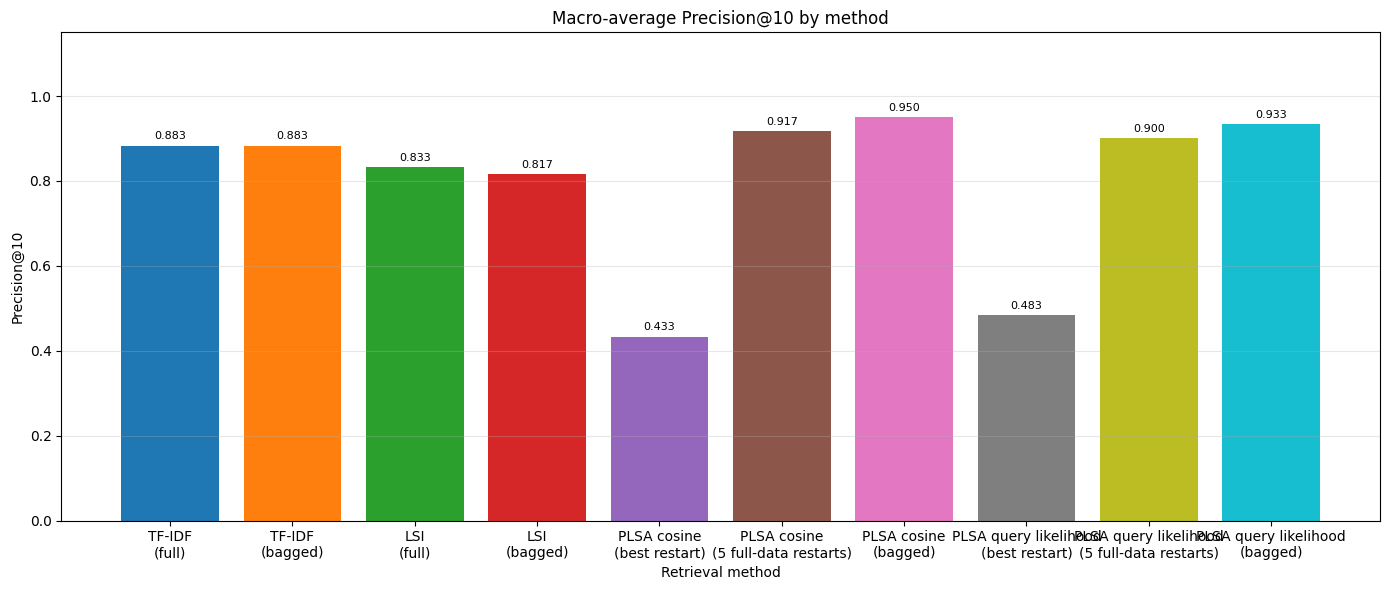

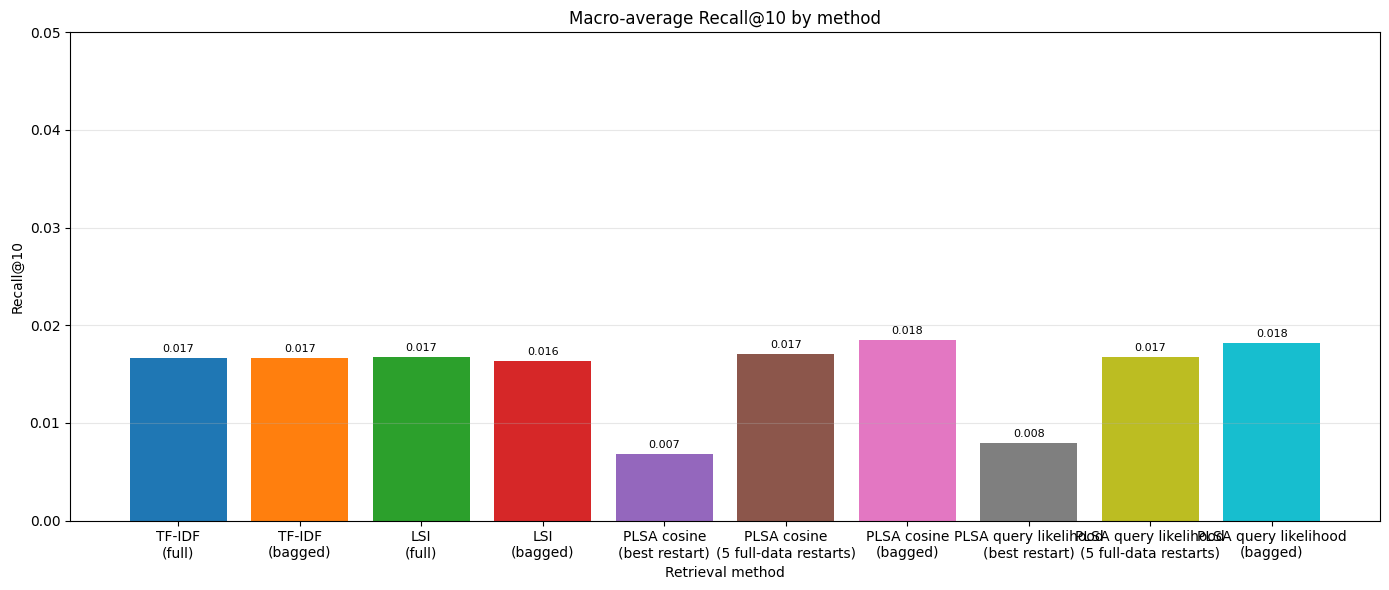

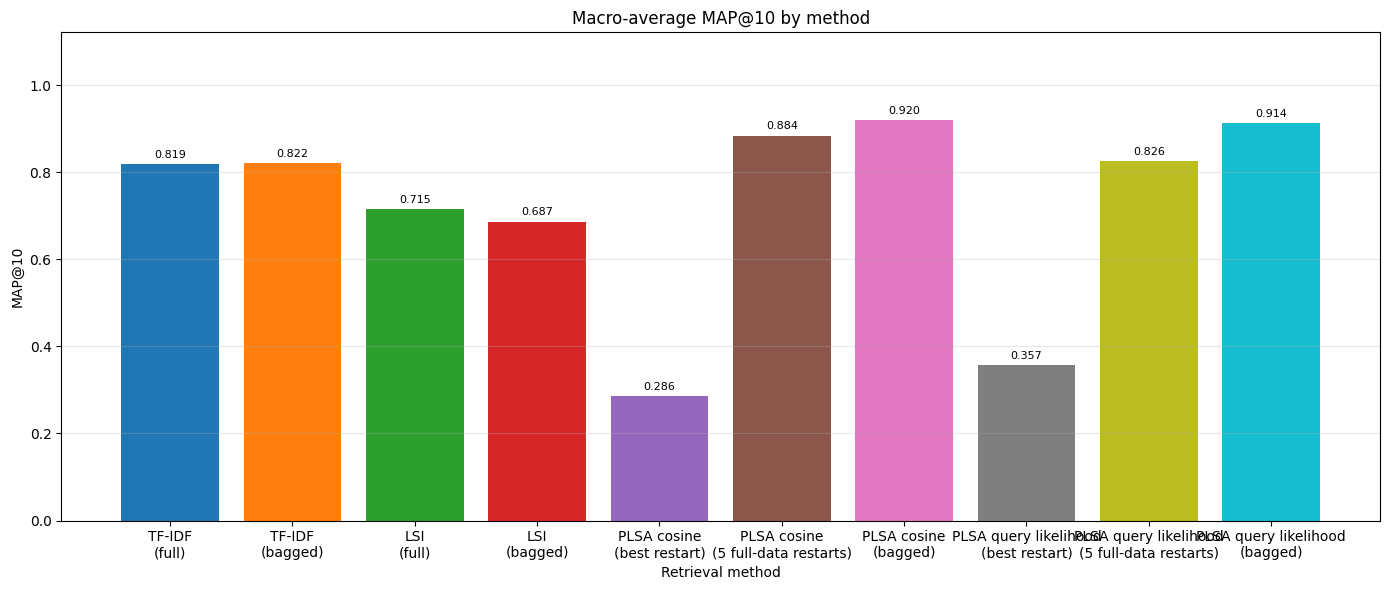

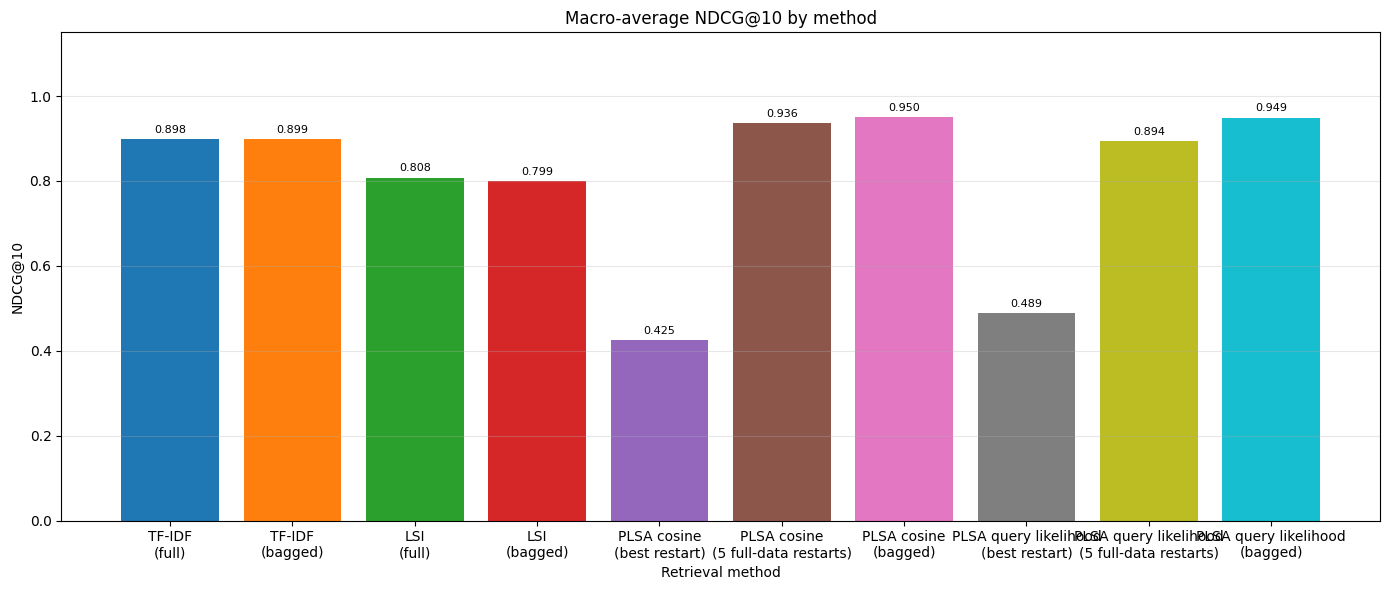

In [11]:
metric_columns = ["Precision@10", "Recall@10", "MAP@10", "NDCG@10"]
method_colors = dict(zip(mean_metrics["Method"], plt.cm.tab10.colors))
method_labels = {
    "TF-IDF/VSM (full)": "TF-IDF\n(full)",
    "TF-IDF/VSM (bagged)": "TF-IDF\n(bagged)",
    "LSI (full)": "LSI\n(full)",
    "LSI (bagged)": "LSI\n(bagged)",
    "PLSA cosine (best restart)": "PLSA cosine\n(best restart)",
    "PLSA cosine (5 restarts)": "PLSA cosine\n(5 full-data restarts)",
    "PLSA cosine (bagged)": "PLSA cosine\n(bagged)",
    "PLSA query likelihood (best restart)": "PLSA query likelihood\n(best restart)",
    "PLSA query likelihood (5 restarts)": "PLSA query likelihood\n(5 full-data restarts)",
    "PLSA query likelihood (bagged)": "PLSA query likelihood\n(bagged)",
}

for metric in metric_columns:
    values = mean_metrics[metric].to_numpy(dtype=float)
    upper_limit = min(1.15, max(0.05, float(values.max()) * 1.22))
    plot_labels = [method_labels[method] for method in mean_metrics["Method"]]
    fig, ax = plt.subplots(figsize=(14, 6))
    bars = ax.bar(plot_labels, values, color=[method_colors[m] for m in mean_metrics["Method"]])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set_ylim(0, upper_limit)
    ax.set_title(f"Macro-average {metric} by method")
    ax.set_ylabel(metric)
    ax.set_xlabel("Retrieval method")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


### Metric plot interpretation

These four charts display the macro-average results summarized above, with one metric per chart and method names on the horizontal axis. They make the large PLSA improvement from aggregation visible without forcing Recall@10 and the other metrics onto a shared scale. Read the per-query and macro-average tables for exact values.